In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

from pyrite.experimental.quantum import AxialDiagnosticConfig, axial_diagnostic
from pyrite.quantum import gaussian

# Axial channeling and wavefunction evolution

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/14-axial-channeling-evolution.py)

Evolve a **0.5 Å** Gaussian through **50 nm** of Si[001] at **5 MeV**,
then inspect density, phase and overlap on a periodic transverse grid.
This experimental coherent diagnostic has no scattering or absorption;
its physical predictions are not rigorously validated.

In [ ]:
config = AxialDiagnosticConfig(
    crystal="silicon",
    axis=(0, 0, 1),
    kinetic_energy_eV=5e6,
    cells=(2, 2),
    shape=(64, 64),
    depths_ang=tuple(np.linspace(0.0, 500.0, 51)),
    step_ang=2.0,
    mode="coherent",
    backend="cpu",
)
entry = gaussian(waist_ang=0.5, dimension=2, center_ang=(1.0, 1.0))

In [ ]:
result = axial_diagnostic(config, entry=entry)
waves = result.wavefunctions_per_ang
overlap = np.abs(np.sum(waves[0].conj() * waves, axis=(1, 2))) ** 2
overlap *= result.grid.cell_area_ang2**2

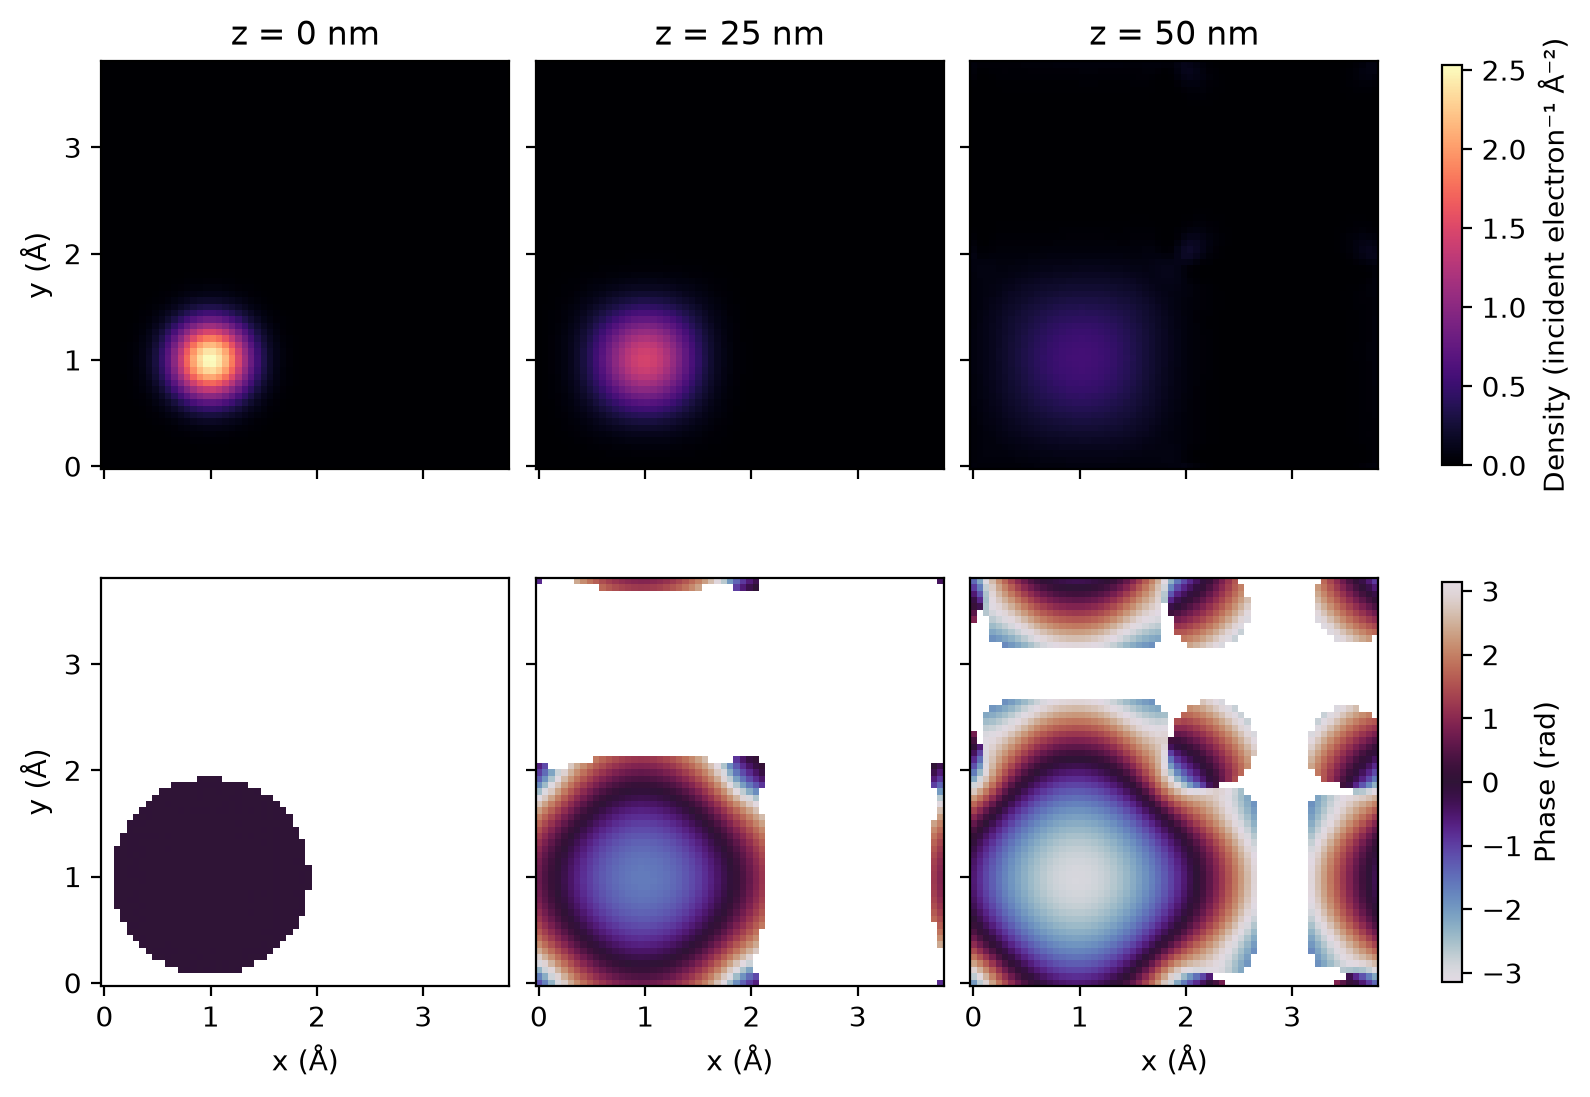

In [ ]:
_snapshots = (0, len(result.depths_ang) // 2, len(result.depths_ang) - 1)
_densities = result.density_per_ang2[list(_snapshots)]
_dx, _dy = result.grid.x[1] - result.grid.x[0], result.grid.y[1] - result.grid.y[0]
_extent = (
    -_dx / 2,
    result.grid.x[-1] + _dx / 2,
    -_dy / 2,
    result.grid.y[-1] + _dy / 2,
)
fig_states, _axes = plt.subplots(
    2, 3, figsize=(8, 5.5), layout="constrained", sharex=True, sharey=True
)
for _column, _index in enumerate(_snapshots):
    _density = result.density_per_ang2[_index]
    _density_image = _axes[0, _column].imshow(
        _density.T,
        origin="lower",
        extent=_extent,
        cmap="magma",
        vmin=0,
        vmax=float(_densities.max()),
    )
    _phase = np.ma.masked_where(_density < _density.max() * 1e-3, np.angle(waves[_index]))
    _phase_image = _axes[1, _column].imshow(
        _phase.T,
        origin="lower",
        extent=_extent,
        cmap="twilight",
        vmin=-np.pi,
        vmax=np.pi,
    )
    _axes[0, _column].set_title(f"z = {result.depths_ang[_index] / 10:g} nm")
    _axes[1, _column].set_xlabel("x (Å)")
_axes[0, 0].set_ylabel("y (Å)")
_axes[1, 0].set_ylabel("y (Å)")
fig_states.colorbar(
    _density_image, ax=_axes[0], shrink=0.8, label="Density (incident electron⁻¹ Å⁻²)"
)
fig_states.colorbar(_phase_image, ax=_axes[1], shrink=0.8, label="Phase (rad)")
fig_states  # noqa: B018 - displayed by marimo

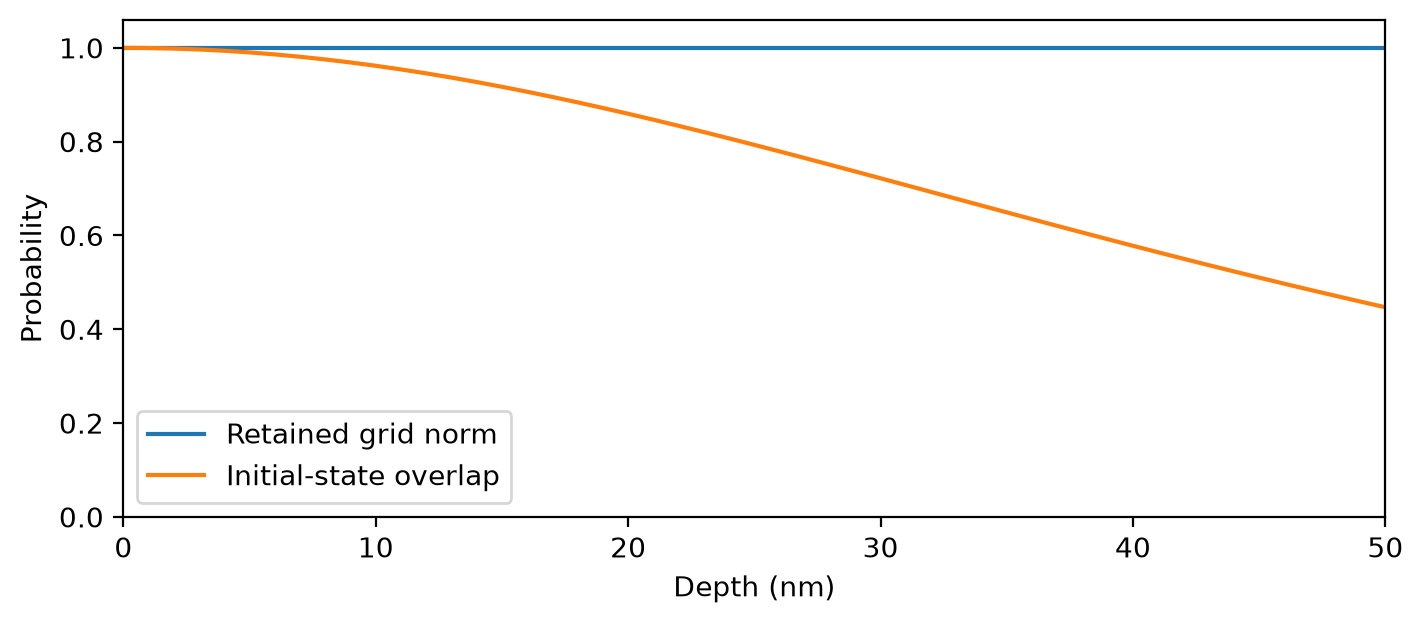

In [ ]:
fig_overlap, _ax = plt.subplots(figsize=(7, 3), layout="constrained")
_ax.plot(result.depths_ang / 10, result.surviving, label="Retained grid norm")
_ax.plot(result.depths_ang / 10, overlap, label="Initial-state overlap")
_ax.set(xlabel="Depth (nm)", ylabel="Probability", ylim=(0, 1.06), xlim=(0, 50))
_ax.legend()
fig_overlap  # noqa: B018 - displayed by marimo

Changing overlap describes coherent redistribution, not particle loss.
The entry is normalized on this finite grid. Grid norm tests unitary
evolution; opposite supercell edges connect periodically. Phase is masked where density is below 0.1% of its peak.

Try changing the waist or depth. Refine supercell size, spatial resolution
and propagation step independently. This direct diagnostic does not admit
axial channeling to production transport.

## Continue learning

Use the [axial diagnostic how-to](../../guides/experimental-axial-channeling.md)
for solver controls and the [quantum API](../../reference/python-api/quantum.md)
for exact signatures.
[Real-space propagation evidence](../../validation/channeling/cr-axial-realspace-propagation.md)
checks periodic-grid normalization and propagation limits.

{download}`Download canonical Marimo notebook <../14-axial-channeling-evolution.py>`